# code_205 · Test graph masks, physical residuals and temporal explanations

**Book:** section 38.5. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_38_GUIDE.md), [execution evidence](../CHAPTER_38_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_205).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Explanation contracts identify the fitted function, target output, reference population, permitted perturbations and action limits. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8005;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
Darwin arm64 CPU; seed 8005


## Explain a learned graph predictor, then test the extracted subgraph
 Eight positive axial springs connect six nodes; node0 is fixed. Stiffness is in kN/mm, load in kN and displacement in mm. These are scalar spring networks with schematic drawing coordinates, not two-dimensional trusses. Generate800 source and200 final independent networks. Assemble each stiffness matrix from edge incidence and solve its five free displacements. Fit a three-layer message-passing network to source nodal displacements. Features contain applied force, weighted degree, support flag and normalized node index; these are declared teaching inputs. Use the first final network, fixed before seeing its error. Freeze the predictor and optimize eight sigmoid edge gates against squared deviation from its original tip prediction plus0.01 times mean gate value. This original retention/sparsity objective is inspired by graph explanation, not a reproduction of GNNExplainer's full mutual-information/feature-mask method. Recompute degrees after every perturbation. Compare the continuous mask and its three largest hard edges. A good continuous fit does not guarantee a faithful hard subgraph or a physically connected mechanism.


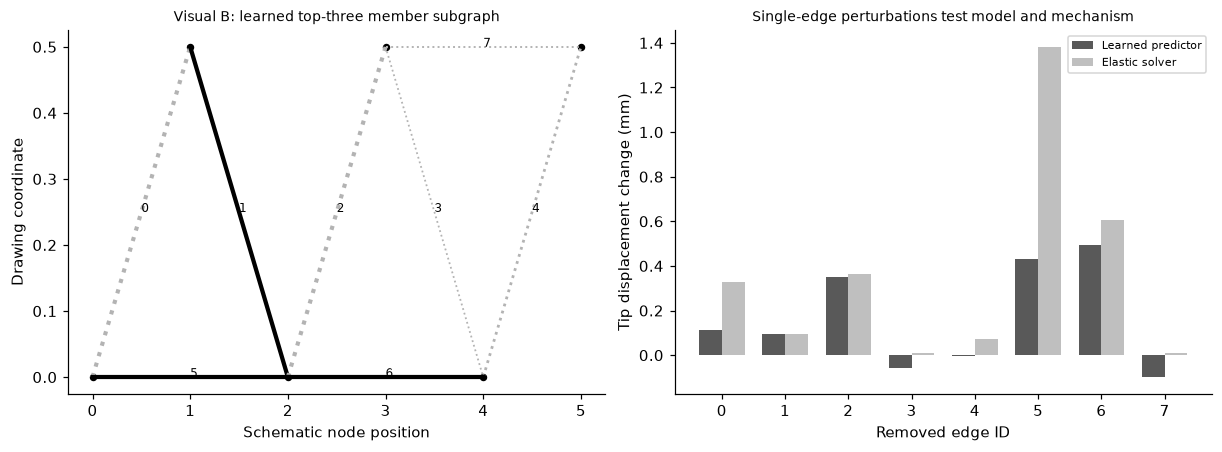

In [2]:
edges=np.array([[0,1],[1,2],[2,3],[3,4],[4,5],[0,2],[2,4],[3,5]]);B=np.zeros((8,6))
for e,(i,j) in enumerate(edges):B[e,i]=1;B[e,j]=-1
def solve(k,force):
    K=np.einsum('be,ei,ej->bij',np.atleast_2d(k),B,B);out=np.zeros((len(K),6));out[:,1:]=np.linalg.solve(K[:,1:,1:],np.atleast_2d(force)[:,1:,None])[...,0];return out,K
def graphs(n):
    k=rng.uniform(.8,1.8,(n,8));f=rng.uniform(0,1,(n,6));f[:,0]=0;u,K=solve(k,f);return k,f,u
ks,fs,us=graphs(800);kf,ff,uf=graphs(200);Bt=torch.tensor(B)
class SpringGNN(nn.Module):
    def __init__(self):
        super().__init__();self.layers=nn.ModuleList([nn.Linear(8,16),nn.Linear(32,16),nn.Linear(32,16)]);self.readout=nn.Linear(32,1)
    def forward(self,k,f):
        A=torch.zeros((len(k),6,6))
        for e,(i,j) in enumerate(edges):A[:,i,j]=k[:,e];A[:,j,i]=k[:,e]
        degree=A.sum(-1);A=A+torch.eye(6);A=A/A.sum(-1,keepdim=True);position=torch.arange(6)/5;support=torch.tensor([1.,0,0,0,0,0]);h=torch.stack([f,degree,support.expand(len(k),-1),position.expand(len(k),-1)],-1)
        for layer in self.layers:h=torch.tanh(layer(torch.cat([h,A@h],dim=-1)))
        out=self.readout(torch.cat([h,h.mean(1,keepdim=True).expand(-1,6,-1)],dim=-1)).squeeze(-1);return out*(1-support)
model=SpringGNN();opt=torch.optim.Adam(model.parameters(),lr=.01);tk,tf,tu=map(torch.tensor,[ks,fs,us])
for _ in range(400):opt.zero_grad();loss=((model(tk,tf)-tu)**2).mean();loss.backward();opt.step()
with torch.no_grad():pred=model(torch.tensor(kf),torch.tensor(ff)).numpy()
qk=torch.tensor(kf[:1]);qf=torch.tensor(ff[:1]);original=float(pred[0,-1])
for parameter in model.parameters():parameter.requires_grad_(False)
gates=nn.Parameter(torch.zeros(8));maskopt=torch.optim.Adam([gates],lr=.05)
for _ in range(300):
    maskopt.zero_grad();mask=torch.sigmoid(gates);retained=model(qk*mask,qf)[0,-1];objective=(retained-original)**2+.01*mask.mean();objective.backward();maskopt.step()
mask=torch.sigmoid(gates).detach().numpy();top=np.argsort(mask)[-3:];hard=np.zeros(8);hard[top]=1
with torch.no_grad():continuous=float(model(qk*torch.tensor(mask),qf)[0,-1]);hardprediction=float(model(qk*torch.tensor(hard),qf)[0,-1])
perturb_model=[];perturb_solver=[]
for e in range(8):
    altered=kf[:1].copy();altered[0,e]=0;true_altered,Kalter=solve(altered,ff[:1]);assert np.linalg.eigvalsh(Kalter[0,1:,1:]).min()>0
    with torch.no_grad():perturb_model.append(float(model(torch.tensor(altered),qf)[0,-1])-original)
    perturb_solver.append(float(true_altered[0,-1]-uf[0,-1]))
RESULTS.update(source_graphs=800,final_graphs=200,graph_final_node_RMSE_mm=float(np.sqrt(np.mean((pred-uf)**2))),graph_final_tip_RMSE_mm=float(np.sqrt(np.mean((pred[:,-1]-uf[:,-1])**2))),fixed_query_true_tip_mm=float(uf[0,-1]),fixed_query_model_tip_mm=original,learned_edge_gates=mask.tolist(),hard_top3_edges=top.tolist(),continuous_mask_tip_error_mm=abs(continuous-original),hard_top3_tip_error_mm=abs(hardprediction-original),single_edge_model_tip_changes_mm=perturb_model,single_edge_solver_tip_changes_mm=perturb_solver,mask_objective='squared original tip prediction deviation + 0.01 mean sigmoid gate',full_GNNExplainer_reproduction=False)
xy=np.array([[0,0],[1,0],[2,0],[3,0],[4,0],[5,0]],float);xy[:,1]=[0,.5,0,.5,0,.5];fig,axes=plt.subplots(1,2,figsize=(11,4))
for e,(i,j) in enumerate(edges):axes[0].plot(xy[[i,j],0],xy[[i,j],1],color='black' if e in top else '.7',linestyle='-' if e in top else ':',linewidth=1+2*mask[e]);axes[0].text(*xy[[i,j]].mean(0),str(e),fontsize=8)
axes[0].scatter(*xy.T,color='black',s=15);axes[0].set(title='Visual B: learned top-three member subgraph',xlabel='Schematic node position',ylabel='Drawing coordinate');xx=np.arange(8);axes[1].bar(xx-.18,perturb_model,.36,label='Learned predictor',color='.35');axes[1].bar(xx+.18,perturb_solver,.36,label='Elastic solver',color='.75');axes[1].set(xticks=xx,xlabel='Removed edge ID',ylabel='Tip displacement change (mm)',title='Single-edge perturbations test model and mechanism');axes[1].legend(fontsize=7);plt.show()


## Map prediction errors and equilibrium residuals in physical units
 The known simulator solution is an independent benchmark for displacement error. A second diagnostic uses only the predicted displacements, measured teaching loads and known stiffness: compute K u_hat - f at the five free nodes. The support displacement is exactly zero by construction, but that architectural boundary condition does not enforce free-node equilibrium. Plot nodewise displacement error in mm and free-node equilibrium residual in kN with separate symmetric colour scales. These maps test a physical concept directly. They do not establish that the explanation mask recovered a causal load path, and small nodal error need not imply a small force residual. Field use would also audit stiffness/force uncertainty and omitted degrees of freedom.


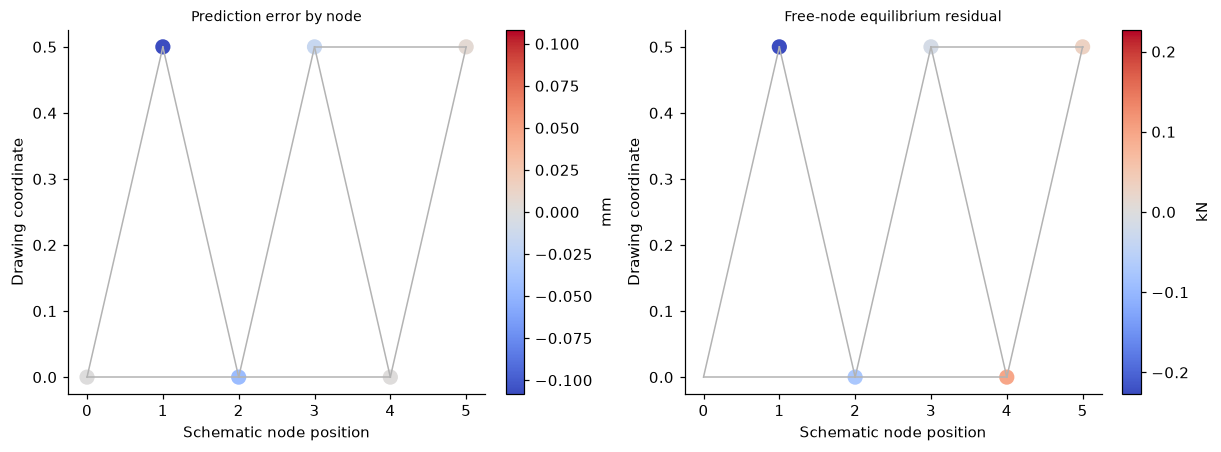

In [3]:
_,K=solve(kf[:1],ff[:1]);error=pred[0]-uf[0];residual=K[0]@pred[0]-ff[0];assert pred[0,0]==0 and np.allclose(K[0,1:,1:]@uf[0,1:],ff[0,1:]);RESULTS.update(query_node_displacement_errors_mm=error.tolist(),query_free_node_equilibrium_residuals_kN=residual[1:].tolist(),query_free_equilibrium_L2_kN=float(np.linalg.norm(residual[1:])),support_displacement_exact=True);fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,values,title,unit,ids in [(axes[0],error,'Prediction error by node','mm',np.arange(6)),(axes[1],residual[1:],'Free-node equilibrium residual','kN',np.arange(1,6))]:
    for i,j in edges:ax.plot(xy[[i,j],0],xy[[i,j],1],color='.7',linewidth=1)
    bound=max(float(np.max(abs(values))),1e-8);sc=ax.scatter(xy[ids,0],xy[ids,1],c=values,cmap='coolwarm',vmin=-bound,vmax=bound,s=80);fig.colorbar(sc,ax=ax,label=unit);ax.set(title=title,xlabel='Schematic node position',ylabel='Drawing coordinate')
plt.show()


## Validate temporal attributions against controlled perturbations
 Generate independent800 source and200 final AR(0.6) sequences of length20. A known noisy target uses the last three values with weights0.7,0.2,-0.1. Fit an actual attention-pooling network with learned positional scores and nonlinear scalar embeddings for400 source updates. Report final RMSE without model selection. For the first final sequence, use the source mean sequence as the integrated-gradients baseline. Integrate input gradients with256 midpoint evaluations and check completeness against the model output difference. Attention weights and normalized absolute integrated gradients answer different internal questions. Replace the top three positions under each explanation with baseline values and compare prediction changes with twenty random three-position controls. This is a model sensitivity test, not proof that the replaced windows are causal interventions. Repeat integrated gradients after resetting all learned parameters, including positional scores, and record their rank correlation. Parameter randomization can reveal dependence on learned weights; neither a favourable nor unfavourable single correlation is a universal explanation-quality guarantee.


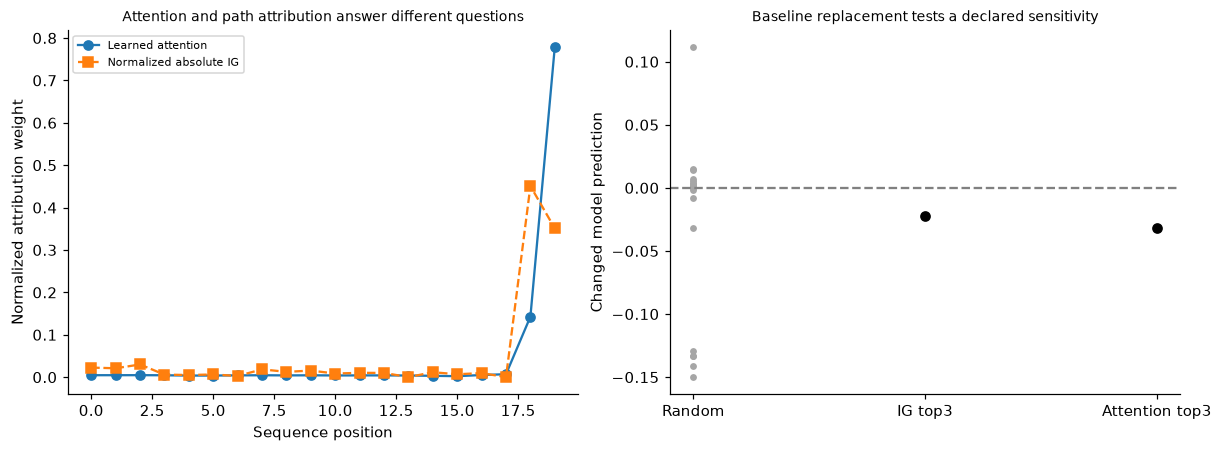

In [4]:
from scipy.stats import spearmanr
def sequences(n):
    x=rng.normal(size=(n,20))
    for t in range(1,20):x[:,t]=.6*x[:,t-1]+np.sqrt(1-.6**2)*x[:,t]
    return x,.7*x[:,-1]+.2*x[:,-2]-.1*x[:,-3]+rng.normal(scale=.05,size=n)
ts,ys=sequences(800);tv,yv=sequences(200)
class TemporalAttention(nn.Module):
    def __init__(self):
        super().__init__();self.embed=nn.Linear(1,8);self.score=nn.Linear(8,1);self.position=nn.Parameter(torch.zeros(20));self.out=nn.Linear(8,1)
    def forward(self,x,return_attention=False):
        h=torch.tanh(self.embed(x[...,None]));a=torch.softmax(self.score(h).squeeze(-1)+self.position,dim=1);p=self.out((a[...,None]*h).sum(1)).squeeze(-1);return (p,a) if return_attention else p
temporal=TemporalAttention();optimizer=torch.optim.Adam(temporal.parameters(),lr=.02);tx,ty=map(torch.tensor,[ts,ys])
for _ in range(400):optimizer.zero_grad();loss=((temporal(tx)-ty)**2).mean();loss.backward();optimizer.step()
with torch.no_grad():testpred=temporal(torch.tensor(tv)).numpy();qp,attention=temporal(torch.tensor(tv[:1]),True)
baseline=torch.tensor(ts.mean(0));query=torch.tensor(tv[0])
def integrated_gradients(net):
    alpha=(torch.arange(256)+.5)/256;path=(baseline+alpha[:,None]*(query-baseline)).requires_grad_(True);gradient=torch.autograd.grad(net(path).sum(),path)[0];return ((query-baseline)*gradient.mean(0)).detach().numpy()
ig=integrated_gradients(temporal)
with torch.no_grad():difference=float(temporal(query[None])[0]-temporal(baseline[None])[0])
assert abs(ig.sum()-difference)<.03
def occlusion(indices):
    altered=query.clone();altered[indices]=baseline[indices]
    with torch.no_grad():return float(temporal(altered[None])[0]-qp[0])
att=attention[0].numpy();igids=np.argsort(abs(ig))[-3:];attids=np.argsort(att)[-3:];controls=[occlusion(rng.choice(20,3,replace=False)) for _ in range(20)];randomized=copy.deepcopy(temporal)
for module in randomized.modules():
    if hasattr(module,'reset_parameters'):module.reset_parameters()
with torch.no_grad():randomized.position.normal_(0,.1)
randomig=integrated_gradients(randomized);correlation=float(spearmanr(ig,randomig).statistic);assert np.isfinite(correlation)
RESULTS.update(temporal_final_RMSE=float(np.sqrt(np.mean((testpred-yv)**2))),attention_weights=att.tolist(),integrated_gradients=ig.tolist(),IG_completeness_error=float(abs(ig.sum()-difference)),IG_quadrature_midpoints=256,IG_top3_positions=igids.tolist(),attention_top3_positions=attids.tolist(),IG_top3_occlusion_change=occlusion(igids),attention_top3_occlusion_change=occlusion(attids),random_three_position_occlusion_changes=controls,parameter_randomization_IG_rank_correlation=correlation,known_generator_nonzero_positions=[17,18,19]);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(range(20),att,'o-',label='Learned attention');axes[0].plot(range(20),abs(ig)/abs(ig).sum(),'s--',label='Normalized absolute IG');axes[0].set(xlabel='Sequence position',ylabel='Normalized attribution weight',title='Attention and path attribution answer different questions');axes[0].legend(fontsize=7);axes[1].scatter(np.zeros(20),controls,color='.65',s=12,label='Random three positions');axes[1].scatter([1,2],[occlusion(igids),occlusion(attids)],color='black');axes[1].axhline(0,color='.5',linestyle='--');axes[1].set(xticks=[0,1,2],xticklabels=['Random','IG top3','Attention top3'],ylabel='Changed model prediction',title='Baseline replacement tests a declared sensitivity');plt.show()


In [5]:
summary={'example_id':'code_205','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual graph neural regression and learned sparse edge mask with hard-mask fidelity checks', 'single-edge model perturbations compared with an independent elastic solver', 'nodewise displacement error and equilibrium residual maps', 'actual learned temporal attention and integrated gradients with occlusion and parameter randomization controls'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual graph neural regression and learned sparse edge mask with hard-mask fidelity checks", "single-edge model perturbations compared with an independent elastic solver", "nodewise displacement error and equilibrium residual maps", "actual learned temporal attention and integrated gradients with occlusion and parameter randomization controls"], "elapsed_seconds": 2.659, "example_id": "code_205", "hardware": "Darwin arm64 CPU", "results": {"IG_completeness_error": 1.3196857634456549e-08, "IG_quadrature_midpoints": 256, "IG_top3_occlusion_change": -0.022576835554094316, "IG_top3_positions": [2, 19, 18], "attention_top3_occlusion_change": -0.03217805292784498, "attention_top3_positions": [17, 18, 19], "attention_weights": [0.004691713951417421, 0.004696796334400801, 0.00475800697860484, 0.004545626589049774, 0.0037750614403492303, 0.0038744870240625447, 0.004290808315739584, 0.004578133497328955, 0.0042211548577602365, 0.0044645812374138